# 02 - Experiments: Vanilla LSTM vs CIFG vs WMC (Drug Review, 3-class sentiment)

**Lab Project on Recurrent Neural Networks - Advanced Natural Language Processing 2026/2027**

All three cells are implemented by hand with `nn.Linear` (see `src/cells.py`); the built-in recurrent layers are not used.
Same data splits, same protocol, same seeds for every model.

**How the notebook is organised**
1. Setup, data loading, sanity check on synthetic data, model sizes and speed benchmark.
2. **Stage A** - base comparison of the three cells (several seeds).
3. **Stage B** - one-factor-at-a-time hyperparameter study (learning rate, optimizer, initialization, batch size, hidden size, class weights).
4. **Stage C** - best setting of each cell (chosen on the **validation** macro-F1) re-run with more seeds.
5. Results: tables, figures (saved in `results/figures/`), confusion matrices and a pre-submission check.

**Resuming after a Colab disconnection:** reconnect, re-run the cells from the top down to the stage you were running.
Finished experiments are read from `results/metrics.csv` and skipped; an interrupted experiment restarts from its last epoch checkpoint.

In [2]:
# ============================ 0. Setup: Google Drive, paths ============================
import os, sys
from pathlib import Path

# >>> EDIT HERE: folder on Google Drive that contains drugsComTrain_raw.* and drugsComTest_raw.* <<<
DATA_DIR = "/content/drive/MyDrive/projet-lstm-drug-review/data"
# Project root on Google Drive (contains src/, notebooks/, results/)
PROJECT_ROOT = "/content/drive/MyDrive/projet-lstm-drug-review"

try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    # Not on Colab (local test): the project root is the parent of the notebooks/ folder.
    print("Not running on Colab: Google Drive is not mounted.")
    PROJECT_ROOT = str(Path.cwd().parent) if Path.cwd().name == "notebooks" else str(Path.cwd())

if not Path(PROJECT_ROOT, "src").is_dir():
    raise FileNotFoundError(
        f"Cannot find the src/ folder in PROJECT_ROOT = {PROJECT_ROOT}\n"
        "Check that you copied the whole project folder to Google Drive and that PROJECT_ROOT is correct.")
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)       # makes 'from src.cells import ...' work
os.chdir(PROJECT_ROOT)
print("Project root:", PROJECT_ROOT)
print("Data folder :", DATA_DIR)

Mounted at /content/drive
Project root: /content/drive/MyDrive/projet-lstm-drug-review
Data folder : /content/drive/MyDrive/projet-lstm-drug-review/data


In [3]:
# Auto-reload is optional. It fails on some Colab versions (Python 3.13: no module 'imp').
try:
    get_ipython().run_line_magic("load_ext", "autoreload")
    get_ipython().run_line_magic("autoreload", "2")
    print("Autoreload enabled.")
except Exception as error:
    print("Autoreload not available, continuing without it:", error)
    print("If you edit a file in src/, restart the runtime (Runtime > Restart session) to use the new code.")

Autoreload not available, continuing without it: No module named 'imp'
If you edit a file in src/, restart the runtime (Runtime > Restart session) to use the new code.


In [4]:
# ===================== Packages, GPU check and seeds =====================
import importlib.metadata as md, re, subprocess, random
import numpy as np

# Install only the packages of requirements.txt that are missing (Colab already has most of them).
missing = []
for line in Path(PROJECT_ROOT, "requirements.txt").read_text().splitlines():
    line = line.split("#")[0].strip()
    if not line:
        continue
    try:
        md.version(re.split(r"[<>=!~\[ ]", line)[0])
    except md.PackageNotFoundError:
        missing.append(line)
if missing:
    print("Installing missing packages:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
else:
    print("All packages from requirements.txt are already installed.")

SEED = 42
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("PyTorch", torch.__version__, "| device:", DEVICE,
          "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "NO GPU")
    if DEVICE.type == "cpu":
        print("WARNING: no GPU detected. In Colab: Runtime > Change runtime type > T4 GPU, then re-run.")
except ImportError:
    DEVICE = None
    print("PyTorch is not installed (only needed for notebook 02).")

All packages from requirements.txt are already installed.
PyTorch 2.11.0+cpu | device: cpu | NO GPU


## 1. Imports, settings and data

In [5]:
from dataclasses import replace
import time, tempfile
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from src import config
from src.cells import CELL_NAMES, CELL_LONG_NAMES
from src.data import DataConfig, prepare_data, write_synthetic_dataset
from src.train import (ExperimentConfig, DeviceData, build_model, count_trainable_parameters, exp_id,
                       make_ofat_configs, run_experiments, select_best_per_cell, benchmark_speed,
                       load_metrics, results_paths, plot_confusion_matrix, plot_grouped_bars,
                       plot_training_curves, DEFAULT_LR, set_seed)
import json

if DEVICE is None:
    raise RuntimeError("PyTorch is required for this notebook.")
PATHS = results_paths(Path(PROJECT_ROOT) / "results")     # metrics.csv, figures/, runs/, checkpoints/ on Drive
PATHS["figures"].mkdir(parents=True, exist_ok=True)
print("Results are saved in:", PATHS["root"])

Results are saved in: /content/drive/MyDrive/projet-lstm-drug-review/results


In [6]:
# ================== EXPERIMENT BUDGET: edit these values to fit your Colab time ==================
TRAIN_FRACTION = 0.3     # fraction of the training split used (stratified, same samples for every model). 1.0 = all data
EPOCHS = 8               # maximum number of epochs per run
PATIENCE = 2             # early stopping on validation macro-F1
SEEDS = [0, 1]           # stage A seeds. Stage B uses SEEDS[0] only.
FINAL_SEEDS = [1, 2]     # stage C: extra seeds for the best setting of each cell (seed SEEDS[0] already exists)

# Base setting shared by the three models. Stage B changes ONE factor at a time around it.
BASE = ExperimentConfig(embed_dim=128, hidden_size=128, num_layers=1, bidirectional=False, pooling="last",
                        dropout=0.3, optimizer="adam", lr=1e-3, init="xavier", batch_size=128,
                        use_class_weights=False, epochs=EPOCHS, patience=PATIENCE,
                        train_fraction=TRAIN_FRACTION, seed=SEEDS[0])

FACTORS = {                                  # Stage B grid (the SGD learning rate comes from DEFAULT_LR)
    "lr": [3e-4, 1e-3, 3e-3],
    "optimizer": ["adam", "sgd", "rmsprop"],
    "init": ["default", "xavier", "orthogonal"],
    "batch_size": [64, 128, 256],
    "hidden_size": [64, 128, 256],
    "use_class_weights": [False, True],
}
print("Default learning rate per optimizer:", DEFAULT_LR)
print("Base setting:", BASE)

Default learning rate per optimizer: {'adam': 0.001, 'rmsprop': 0.001, 'sgd': 0.05}
Base setting: ExperimentConfig(cell='lstm', embed_dim=128, hidden_size=128, num_layers=1, bidirectional=False, pooling='last', dropout=0.3, optimizer='adam', lr=0.001, weight_decay=0.0, momentum=0.9, init='xavier', forget_bias=1.0, batch_size=128, epochs=8, patience=2, grad_clip=1.0, use_class_weights=False, train_fraction=0.3, seed=0, stage='base')


In [7]:
# Prepared data (single fixed split). Loaded from the cache written by notebook 01 when it exists.
DATA_CFG = DataConfig()
data = prepare_data(DATA_DIR, DATA_CFG, cache_dir=config.CACHE_DIR)
device_data = DeviceData(data, DEVICE)
print("Classes:", data.class_names, "| vocabulary:", len(data.vocab), "| train subset used:",
      len(device_data.train(TRAIN_FRACTION)), "of", len(data.splits["train"]), "reviews")

[data] Loaded prepared data from cache: /content/drive/MyDrive/projet-lstm-drug-review/cache/prepared_00521724e49c.npz
Classes: ['negative', 'neutral', 'positive'] | vocabulary: 23611 | train subset used: 43550 of 145166 reviews


### 1.1 Sanity check on synthetic data (about a minute, results are thrown away)
Checks that the three cells train end-to-end on this machine. **These numbers mean nothing** (fake data).

In [8]:
with tempfile.TemporaryDirectory() as tmp:
    write_synthetic_dataset(Path(tmp) / "data", n_train=600, n_test=200)
    toy = prepare_data(Path(tmp) / "data", DataConfig(max_len=40, min_freq=1), verbose=False)
    toy_data = DeviceData(toy, DEVICE)
    toy_cfgs = [ExperimentConfig(cell=c, embed_dim=16, hidden_size=16, epochs=2, patience=2, batch_size=64)
                for c in CELL_NAMES]
    toy_metrics = run_experiments(toy_cfgs, toy_data, DEVICE, results_dir=Path(tmp) / "results",
                                  save_run_figures=False, verbose=False)
display(toy_metrics[["cell", "n_params", "epochs_run", "val_macro_f1", "test_acc", "status"]])
print("Sanity check passed: the pipeline runs without shape errors." if (toy_metrics["status"] == "ok").all()
      else "Something went wrong, read the messages above.")

[experiments] 3 configurations, 0 already done, 3 to run.
[1/3] Vanilla LSTM | lstm_h16_L1_last_adam_lr0.001_xavier_bs64_nocw_frac1_seed0_6edba4
  -> test acc 0.6050 | test macro-F1 0.3624 | params 2,931 | time 1s | status ok
[2/3] CIFG | cifg_h16_L1_last_adam_lr0.001_xavier_bs64_nocw_frac1_seed0_8f3b4f
  -> test acc 0.4750 | test macro-F1 0.3314 | params 2,403 | time 0s | status ok
[3/3] WMC | wmc_h16_L1_last_adam_lr0.001_xavier_bs64_nocw_frac1_seed0_b9cbbc
  -> test acc 0.4850 | test macro-F1 0.4220 | params 3,699 | time 1s | status ok


,cell,n_params,epochs_run,val_macro_f1,test_acc,status
0,lstm,2931,2,0.297314,0.605,ok
1,cifg,2403,2,0.205079,0.475,ok
2,wmc,3699,2,0.565476,0.485,ok


Sanity check passed: the pipeline runs without shape errors.


### 1.2 Model sizes (trainable parameters) and speed benchmark

In [9]:
rows = []
for cell in CELL_NAMES:
    model = build_model(replace(BASE, cell=cell), len(data.vocab), data.n_classes)
    rows.append({"model": CELL_LONG_NAMES[cell], "trainable parameters (total)": count_trainable_parameters(model),
                 "of which recurrent cell": sum(p.numel() for p in model.cell_parameters())})
display(pd.DataFrame(rows).set_index("model"))
print("The embedding table (vocabulary x embed_dim) is identical for the three models; "
      "the difference between models comes from the recurrent cell only.")

,trainable parameters (total),of which recurrent cell
model,,
Vanilla LSTM,3154179,131584
CIFG,3121283,98688
WMC,3203331,180736


The embedding table (vocabulary x embed_dim) is identical for the three models; the difference between models comes from the recurrent cell only.


In [10]:
stage_a = [replace(c, seed=s, stage="base") for s in SEEDS for c in make_ofat_configs(BASE, {})]
stage_b = make_ofat_configs(BASE, FACTORS)
bench = []
for cell in CELL_NAMES:
    info = benchmark_speed(replace(BASE, cell=cell), device_data, DEVICE)
    bench.append({"model": CELL_LONG_NAMES[cell], "seconds / batch": round(info["seconds_per_batch"], 4),
                  "batches / epoch": info["batches_per_epoch"], "estimated seconds / epoch": round(info["seconds_per_epoch"], 1)})
bench = pd.DataFrame(bench).set_index("model")
display(bench)

n_runs = len({exp_id(c) for c in stage_a + stage_b})
mean_epoch = bench["estimated seconds / epoch"].mean()
print(f"Stage A + B: {n_runs} runs. Rough UPPER bound without early stopping: "
      f"{n_runs * EPOCHS * mean_epoch / 3600:.1f} hours (large hidden sizes and batch sizes change this).")
print("If this is too long: lower TRAIN_FRACTION, EPOCHS or the lists in FACTORS, then re-run from the settings cell.")

,seconds / batch,batches / epoch,estimated seconds / epoch
model,,,
Vanilla LSTM,6.0232,341,2053.9
CIFG,2.6739,341,911.8
WMC,6.1419,341,2094.4


Stage A + B: 39 runs. Rough UPPER bound without early stopping: 146.2 hours (large hidden sizes and batch sizes change this).
If this is too long: lower TRAIN_FRACTION, EPOCHS or the lists in FACTORS, then re-run from the settings cell.


## 2. Stage A - base comparison of the three cells (several seeds)

In [ ]:
metrics = run_experiments(stage_a, device_data, DEVICE, results_dir=PATHS["root"])
display(metrics[metrics["stage"] == "base"][["cell", "seed", "n_params", "epochs_run", "best_epoch",
        "train_time_s", "val_macro_f1", "test_acc", "test_macro_f1"]].round(4))

[experiments] 6 configurations, 0 already done, 6 to run.
[1/6] Vanilla LSTM | lstm_h128_L1_last_adam_lr0.001_xavier_bs128_nocw_frac0.3_seed0_dc171b
  epoch 01/8 | train loss 0.7768 acc 0.6827 | val loss 0.7245 acc 0.7331 macro-F1 0.4641 | 71.7s
  epoch 02/8 | train loss 0.6504 acc 0.7509 | val loss 0.7547 acc 0.7454 macro-F1 0.4821 | 70.8s
  epoch 03/8 | train loss 0.5894 acc 0.7783 | val loss 0.7518 acc 0.7645 macro-F1 0.5014 | 71.2s
  epoch 04/8 | train loss 0.5508 acc 0.7953 | val loss 0.6463 acc 0.7861 macro-F1 0.5250 | 70.9s
  epoch 05/8 | train loss 0.5256 acc 0.8039 | val loss 0.6350 acc 0.7906 macro-F1 0.5297 | 70.7s
  epoch 06/8 | train loss 0.4985 acc 0.8149 | val loss 0.6470 acc 0.7967 macro-F1 0.5357 | 70.9s
  epoch 07/8 | train loss 0.4738 acc 0.8227 | val loss 0.6026 acc 0.8079 macro-F1 0.5500 | 70.7s
  epoch 08/8 | train loss 0.4501 acc 0.8313 | val loss 0.6025 acc 0.8043 macro-F1 0.5526 | 70.9s
  -> test acc 0.7979 | test macro-F1 0.5537 | params 3,154,179 | time 568s 

,cell,seed,n_params,epochs_run,best_epoch,train_time_s,val_macro_f1,test_acc,test_macro_f1
0,lstm,0,3154179,8,8,567.84,0.5526,0.7979,0.5537
1,cifg,0,3121283,8,8,487.14,0.5713,0.8049,0.5616
2,wmc,0,3203331,8,8,691.68,0.5749,0.8078,0.5755
3,lstm,1,3154179,8,7,563.10,0.5491,0.8023,0.5493
4,cifg,1,3121283,8,8,485.00,0.5666,0.8062,0.5593
5,wmc,1,3203331,8,8,688.56,0.5675,0.8036,0.5635


## 3. Stage B - hyperparameter study (one factor at a time, seed = SEEDS[0])
Learning rate, optimizer, weight initialization, batch size, hidden size and class weights are varied one at a time
around `BASE`, for each of the three cells. You can stop this cell at any time and run it again later: finished runs are skipped.

In [ ]:
print(f"{len(stage_b)} configurations in stage B")
metrics = run_experiments(stage_b, device_data, DEVICE, results_dir=PATHS["root"])

36 configurations in stage B
[experiments] 36 configurations, 36 already done, 0 to run.
[1/36] skip (already in metrics.csv): lstm_h128_L1_last_adam_lr0.001_xavier_bs128_nocw_frac0.3_seed0_dc171b
[2/36] skip (already in metrics.csv): cifg_h128_L1_last_adam_lr0.001_xavier_bs128_nocw_frac0.3_seed0_001a5d
[3/36] skip (already in metrics.csv): wmc_h128_L1_last_adam_lr0.001_xavier_bs128_nocw_frac0.3_seed0_bd2f90
[4/36] skip (already in metrics.csv): lstm_h128_L1_last_adam_lr0.0003_xavier_bs128_nocw_frac0.3_seed0_ba8ecd
[5/36] skip (already in metrics.csv): cifg_h128_L1_last_adam_lr0.0003_xavier_bs128_nocw_frac0.3_seed0_c84c5b
[6/36] skip (already in metrics.csv): wmc_h128_L1_last_adam_lr0.0003_xavier_bs128_nocw_frac0.3_seed0_ce7544
[7/36] skip (already in metrics.csv): lstm_h128_L1_last_adam_lr0.003_xavier_bs128_nocw_frac0.3_seed0_0d499d
[8/36] skip (already in metrics.csv): cifg_h128_L1_last_adam_lr0.003_xavier_bs128_nocw_frac0.3_seed0_ff462b
[9/36] skip (already in metrics.csv): wmc_h128

## 4. Stage C - best setting of each cell, re-run with more seeds
The best setting is chosen with the **validation** macro-F1 only (never with the test set).

In [ ]:
metrics = load_metrics(PATHS["metrics"])
best = select_best_per_cell(metrics, seed=SEEDS[0], metric="val_macro_f1")
for cell, cfg in best.items():
    print(f"{CELL_LONG_NAMES[cell]:>13}: optimizer={cfg.optimizer} lr={cfg.lr:g} init={cfg.init} batch={cfg.batch_size} "
          f"hidden={cfg.hidden_size} class_weights={cfg.use_class_weights}")
stage_c = [replace(cfg, seed=s, stage="final") for cfg in best.values() for s in [SEEDS[0]] + FINAL_SEEDS]
metrics = run_experiments(stage_c, device_data, DEVICE, results_dir=PATHS["root"])

 Vanilla LSTM: optimizer=adam lr=0.001 init=xavier batch=128 hidden=256 class_weights=False
         CIFG: optimizer=adam lr=0.001 init=xavier batch=128 hidden=128 class_weights=True
          WMC: optimizer=adam lr=0.001 init=xavier batch=128 hidden=256 class_weights=False
[experiments] 9 configurations, 3 already done, 6 to run.
[1/9] skip (already in metrics.csv): lstm_h256_L1_last_adam_lr0.001_xavier_bs128_nocw_frac0.3_seed0_8c3e04
[2/9] Vanilla LSTM | lstm_h256_L1_last_adam_lr0.001_xavier_bs128_nocw_frac0.3_seed1_0b326d
  epoch 01/8 | train loss 0.7502 acc 0.6984 | val loss 0.6687 acc 0.7468 macro-F1 0.4920 | 116.0s
  epoch 02/8 | train loss 0.6252 acc 0.7612 | val loss 0.6510 acc 0.7631 macro-F1 0.5074 | 116.3s
  epoch 03/8 | train loss 0.5632 acc 0.7898 | val loss 0.5986 acc 0.7930 macro-F1 0.5278 | 116.5s
  epoch 04/8 | train loss 0.5192 acc 0.8048 | val loss 0.5466 acc 0.7966 macro-F1 0.5517 | 116.5s
  epoch 05/8 | train loss 0.4757 acc 0.8221 | val loss 0.5501 acc 0.7976 macr

## 5. Results

### 5.1 Final comparison (mean and standard deviation over seeds, best setting of each cell)

In [12]:
metrics = load_metrics(PATHS["metrics"])
ok = metrics[metrics["status"] == "ok"]
KEY = ["cell", "optimizer", "lr", "init", "batch_size", "hidden_size", "use_class_weights", "embed_dim",
       "num_layers", "pooling", "dropout", "train_fraction", "epochs"]

def runs_of(cfg):
    """All finished runs of metrics.csv that share the setting `cfg` (any seed)."""
    mask = pd.Series(True, index=ok.index)
    for key in KEY:
        mask &= ok[key] == getattr(cfg, key)
    return ok[mask]

final_rows, final_runs = [], {}
for cell, cfg in select_best_per_cell(ok, seed=SEEDS[0]).items():
    runs = runs_of(cfg)
    final_runs[cell] = runs
    final_rows.append({
        "model": CELL_LONG_NAMES[cell], "seeds": len(runs),
        "test accuracy": f"{runs.test_acc.mean():.4f} +/- {runs.test_acc.std(ddof=1):.4f}",
        "test macro-F1": f"{runs.test_macro_f1.mean():.4f} +/- {runs.test_macro_f1.std(ddof=1):.4f}",
        "trainable params": int(runs.n_params.iloc[0]), "cell params": int(runs.n_params_cell.iloc[0]),
        "train time / run (s)": round(runs.train_time_s.mean(), 1), "epochs run": round(runs.epochs_run.mean(), 1),
        "setting": f"{cfg.optimizer}, lr={cfg.lr:g}, {cfg.init}, bs={cfg.batch_size}, H={cfg.hidden_size}, cw={cfg.use_class_weights}"})
final_table = pd.DataFrame(final_rows).set_index("model")
display(final_table)
final_table.to_csv(PATHS["root"] / "final_comparison.csv")

,seeds,test accuracy,test macro-F1,trainable params,cell params,train time / run (s),epochs run,setting
model,,,,,,,,
Vanilla LSTM,3,0.8052 +/- 0.0032,0.6082 +/- 0.0165,3417219,394240,927.3,8.0,"adam, lr=0.001, xavier, bs=128, H=256, cw=False"
CIFG,3,0.7337 +/- 0.0111,0.6146 +/- 0.0021,3121283,98688,488.0,8.0,"adam, lr=0.001, xavier, bs=128, H=128, cw=True"
WMC,3,0.8098 +/- 0.0037,0.6174 +/- 0.0110,3613827,590848,1061.4,8.0,"adam, lr=0.001, xavier, bs=128, H=256, cw=False"


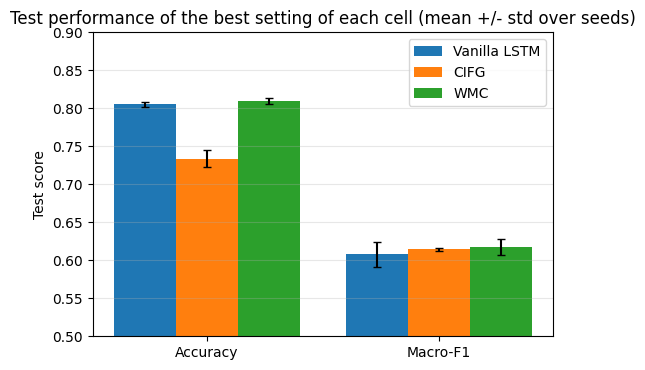

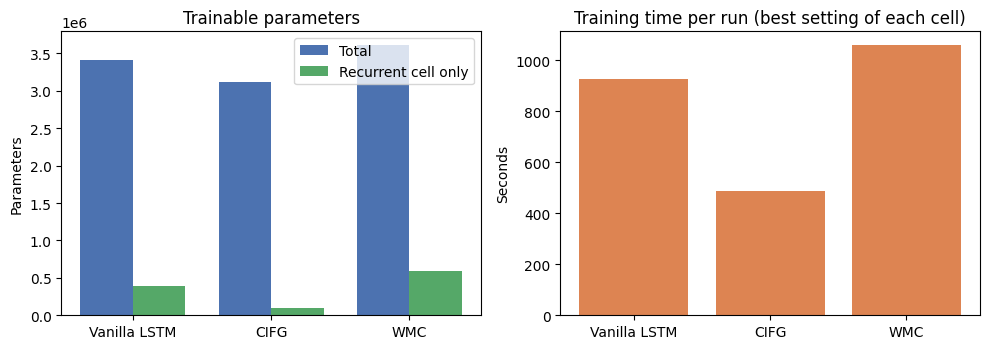

In [13]:
# Bar charts: performance (mean +/- std over seeds), size and training time
perf = pd.DataFrame({m: [final_runs[c][m].mean() for c in final_runs] for m in ("test_acc", "test_macro_f1")},
                    index=[CELL_LONG_NAMES[c] for c in final_runs]).T
err = pd.DataFrame({m: [final_runs[c][m].std(ddof=1) for c in final_runs] for m in ("test_acc", "test_macro_f1")},
                   index=[CELL_LONG_NAMES[c] for c in final_runs]).T
perf.index = ["Accuracy", "Macro-F1"]; err.index = perf.index
plot_grouped_bars(perf, "Test score", "Test performance of the best setting of each cell (mean +/- std over seeds)",
                  path=PATHS["figures"] / "model_comparison.png", errors=err, ylim=(0.5, 0.9))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
labels = [CELL_LONG_NAMES[c] for c in final_runs]
x = np.arange(len(labels)); w = 0.38
axes[0].bar(x - w/2, [final_runs[c].n_params.iloc[0] for c in final_runs], w, color="#4C72B0", label="Total")
axes[0].bar(x + w/2, [final_runs[c].n_params_cell.iloc[0] for c in final_runs], w, color="#55A868", label="Recurrent cell only")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels)
axes[0].set_title("Trainable parameters"); axes[0].set_ylabel("Parameters"); axes[0].legend()
axes[1].bar(labels, [final_runs[c].train_time_s.mean() for c in final_runs], color="#DD8452")
axes[1].set_title("Training time per run (best setting of each cell)"); axes[1].set_ylabel("Seconds")
plt.tight_layout(); plt.savefig(PATHS["figures"] / "params_and_time.png", dpi=130); plt.show()

### 5.2 Per-class results
Macro-F1 treats the three classes equally; the table shows which class is hard (usually *neutral*).

In [14]:
f1_cols = [f"test_f1_{n}" for n in data.class_names]
per_class = pd.DataFrame({CELL_LONG_NAMES[c]: final_runs[c][f1_cols].mean() for c in final_runs}).T
per_class.columns = data.class_names
display(per_class.round(4))

,negative,neutral,positive
Vanilla LSTM,0.7373,0.2001,0.8871
CIFG,0.6839,0.3135,0.8462
WMC,0.7443,0.2177,0.8904


### 5.3 Hyperparameter study (stage B, validation macro-F1, seed = SEEDS[0])

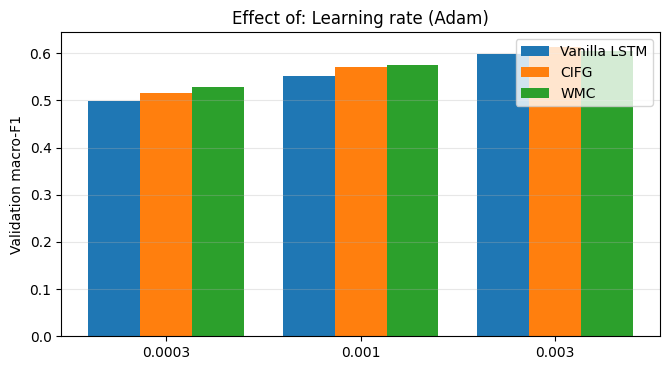

cell,lstm,cifg,wmc
lr,,,
0.0003,0.4989,0.5148,0.5279
0.0010,0.5526,0.5713,0.5749
0.0030,0.5990,0.6138,0.6049


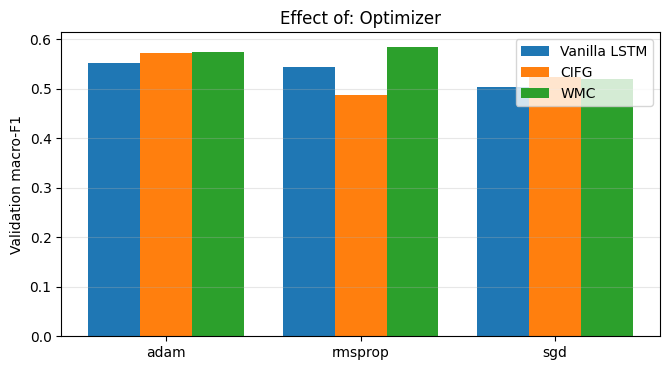

cell,lstm,cifg,wmc
optimizer,,,
adam,0.5526,0.5713,0.5749
rmsprop,0.5446,0.4866,0.5845
sgd,0.5038,0.5237,0.5192


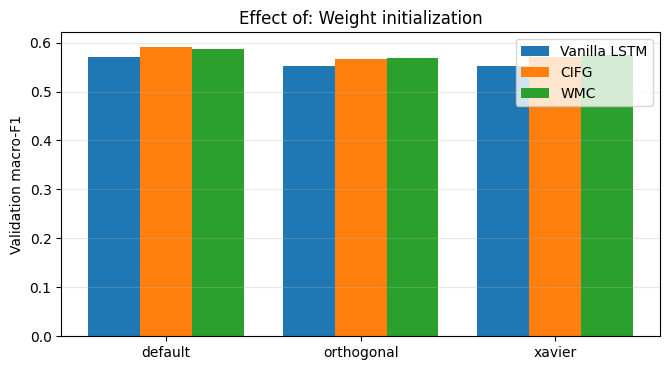

cell,lstm,cifg,wmc
init,,,
default,0.5698,0.5913,0.5863
orthogonal,0.5513,0.5669,0.5680
xavier,0.5526,0.5713,0.5749


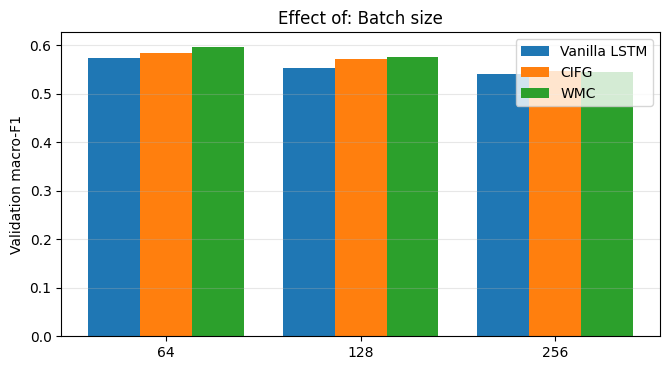

cell,lstm,cifg,wmc
batch_size,,,
64,0.5743,0.5836,0.5967
128,0.5526,0.5713,0.5749
256,0.5404,0.5479,0.5449


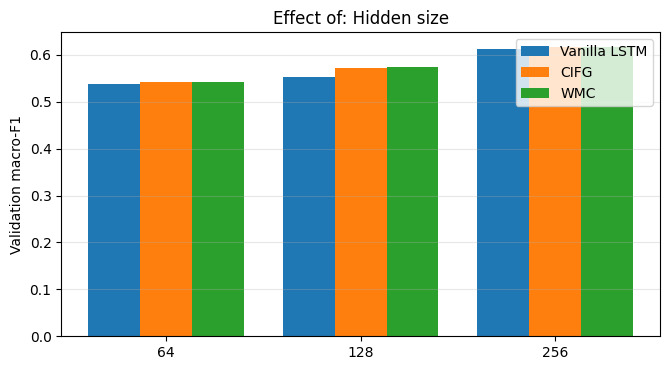

cell,lstm,cifg,wmc
hidden_size,,,
64,0.5374,0.5425,0.5425
128,0.5526,0.5713,0.5749
256,0.6129,0.6173,0.6173


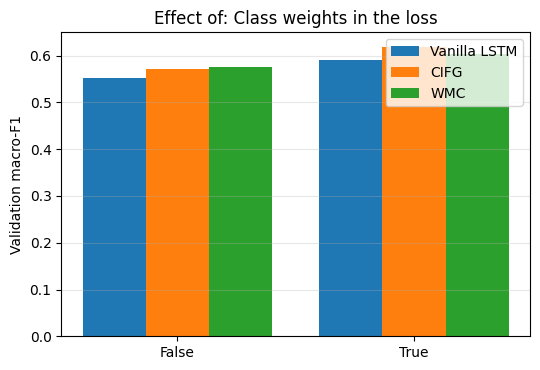

cell,lstm,cifg,wmc
use_class_weights,,,
False,0.5526,0.5713,0.5749
True,0.5913,0.6189,0.6043


In [15]:
def factor_slice(df, factor):
    """Runs of stage A/B in which every OTHER factor is at its base value."""
    sub = df[(df["seed"] == SEEDS[0]) & df["stage"].isin(["base", "ofat"])]
    for other in FACTORS:
        if other == factor or (factor == "optimizer" and other == "lr"):
            continue                      # when the optimizer changes, its learning rate changes with it
        sub = sub[sub[other] == getattr(BASE, other)]
    if factor == "optimizer":
        # keep each optimizer only at ITS default learning rate; otherwise the three
        # Adam learning rates (3e-4, 1e-3, 3e-3) would be averaged together
        keep = pd.Series([np.isclose(lr, DEFAULT_LR[opt])
                          for opt, lr in zip(sub["optimizer"], sub["lr"])], index=sub.index)
        sub = sub[keep]
    return sub

HP_TITLES = {"lr": "Learning rate (Adam)", "optimizer": "Optimizer", "init": "Weight initialization",
             "batch_size": "Batch size", "hidden_size": "Hidden size", "use_class_weights": "Class weights in the loss"}
hp_tables = {}
for factor in FACTORS:
    sub = factor_slice(ok, factor)
    if sub.empty:
        print(f"[{factor}] no finished run yet"); continue
    table = sub.pivot_table(index=factor, columns="cell", values="val_macro_f1")[[c for c in CELL_NAMES if c in sub["cell"].values]]
    hp_tables[factor] = table
    plot_grouped_bars(table, "Validation macro-F1", f"Effect of: {HP_TITLES[factor]}",
                      path=PATHS["figures"] / f"hp_{factor}.png")
    display(table.round(4))

In [16]:
# Class weights: do they help macro-F1 and what do they cost in accuracy?
sub = factor_slice(ok, "use_class_weights")
if not sub.empty:
    both = sub.pivot_table(index="use_class_weights", columns="cell", values=["val_acc", "val_macro_f1"])
    display(both.round(4))
    for cell in CELL_NAMES:
        gain = sub[(sub.cell == cell) & sub.use_class_weights].val_macro_f1.mean() - \
               sub[(sub.cell == cell) & ~sub.use_class_weights].val_macro_f1.mean()
        print(f"{CELL_LONG_NAMES[cell]:>13}: change of validation macro-F1 with class weights = {gain:+.4f}")

val_acc                 val_macro_f1                
cell                 cifg    lstm     wmc         cifg    lstm     wmc
use_class_weights                                                     
False              0.8124  0.8043  0.8140       0.5713  0.5526  0.5749
True               0.7360  0.7315  0.7548       0.6189  0.5913  0.6043

 Vanilla LSTM: change of validation macro-F1 with class weights = +0.0386
         CIFG: change of validation macro-F1 with class weights = +0.0476
          WMC: change of validation macro-F1 with class weights = +0.0294


### 5.4 Learning curves of the best runs

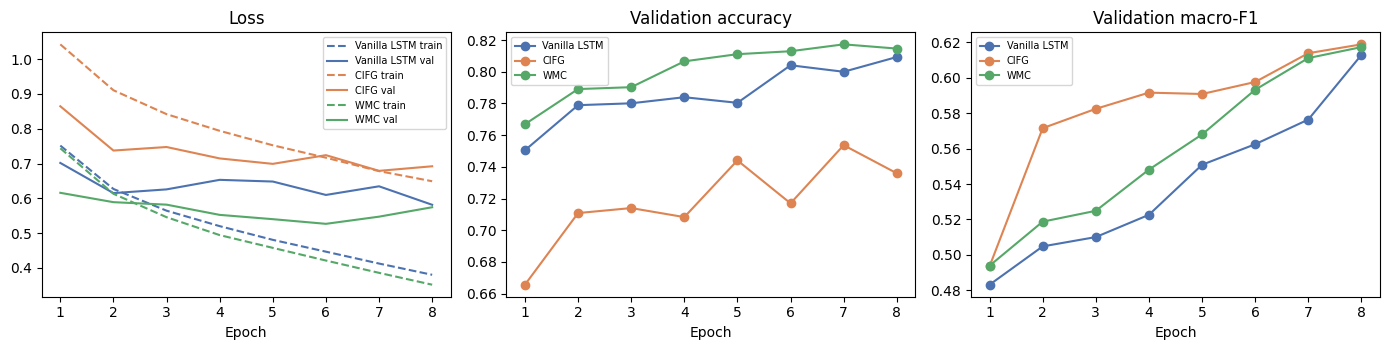

In [17]:
def load_run(eid):
    with open(PATHS["runs"] / f"{eid}.json") as handle:
        return json.load(handle)

best_cfgs = select_best_per_cell(ok, seed=SEEDS[0])
best_runs = {cell: load_run(exp_id(cfg)) for cell, cfg in best_cfgs.items()}
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
COLORS = {"lstm": "#4C72B0", "cifg": "#DD8452", "wmc": "#55A868"}
for cell, run in best_runs.items():
    h = run["history"]; ep = [x["epoch"] for x in h]; label = CELL_LONG_NAMES[cell]
    color = COLORS[cell]
    axes[0].plot(ep, [x["train_loss"] for x in h], "--", color=color, label=f"{label} train")
    axes[0].plot(ep, [x["val_loss"] for x in h], "-", color=color, label=f"{label} val")
    axes[1].plot(ep, [x["val_acc"] for x in h], "o-", color=color, label=label)
    axes[2].plot(ep, [x["val_macro_f1"] for x in h], "o-", color=color, label=label)
for ax, title in zip(axes, ["Loss", "Validation accuracy", "Validation macro-F1"]):
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(PATHS["figures"] / "learning_curves_best.png", dpi=130); plt.show()

### 5.5 Confusion matrices on the test set (best run of each cell)

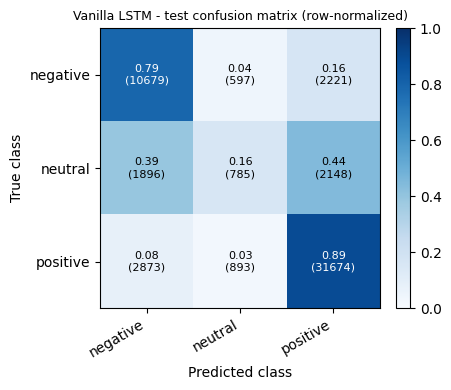

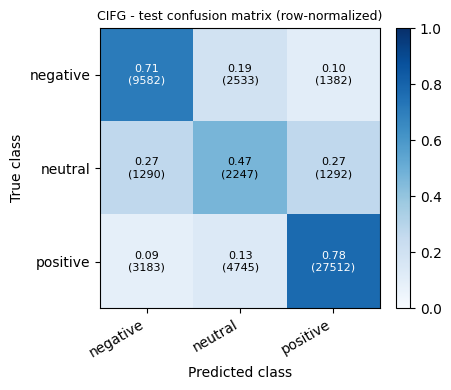

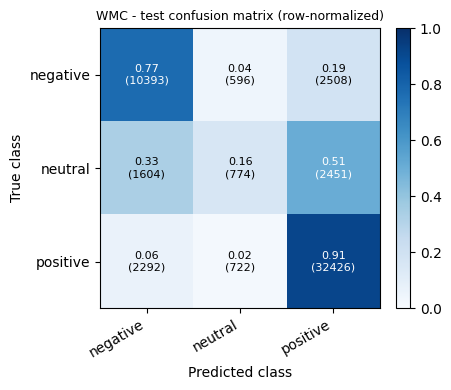

In [ ]:
import numpy as np
for cell, run in best_runs.items():
    plot_confusion_matrix(np.array(run["test_confusion"]), data.class_names,
                          title=f"{CELL_LONG_NAMES[cell]} - test confusion matrix (row-normalized)",
                          path=PATHS["figures"] / f"confusion_{cell}.png", show=True)

### 5.6 Analysis notes
* **Best cell.** In the final comparison (best setting of each cell, 3 seeds), test macro-F1 is 0.617 ± 0.011 for WMC, 0.615 ± 0.002 for CIFG and 0.608 ± 0.017 for Vanilla LSTM. The gaps (0.003 to 0.009) are smaller than the seed-to-seed standard deviation of the LSTM and WMC runs, so no cell is clearly better. Under identical settings (stage A: H=128, no class weights, 2 seeds), the order is WMC (0.570) > CIFG (0.560) > LSTM (0.552) in test macro-F1, and it holds for both seeds, but the gaps are small (WMC − LSTM = 0.018, WMC − CIFG = 0.009).
* **CIFG accuracy.** CIFG's lower final accuracy (0.734) comes from its class-weighted loss, not from the cell: without class weights it reaches 0.805-0.806 test accuracy in stage A, like the other cells (0.798-0.808). At H=128 CIFG has 25% fewer recurrent parameters than the LSTM (98,688 vs 131,584) and is the fastest (about 486 s per run vs 565 s for the LSTM). WMC adds 3H^2 = 49,152 parameters over the LSTM (180,736 vs 131,584), is the slowest (about 690 s) and gains at most 0.01-0.02 macro-F1. The total model sizes differ by less than 3% in stage A (3.12M to 3.20M), because the embedding layer holds most of the parameters.
* **Hyperparameters (stage B, validation macro-F1, one seed).** Learning rate 3e-3 (+0.03 to +0.05 over 1e-3), hidden size 256 (+0.04 to +0.06) and class weights (+0.03 to +0.05) matter most; batch size 64 and the default initialization give smaller gains (about +0.01 to +0.02). SGD is the weakest optimizer overall (0.50-0.52 vs 0.55-0.57 for Adam), probably because it needs more than 8 epochs. RMSprop is the best optimizer for WMC (0.585) but unstable for CIFG (0.487). The three cells react in the same way to most factors. Several best values sit at the edge of the grid (lr 3e-3, H=256, batch size 64), so larger values could be better.
* **Class weights.** Macro-F1 rises by +0.03 to +0.05, but validation accuracy drops by 0.06 to 0.08, because the model predicts the minority classes more often. The neutral class stays the hardest (test F1 0.20-0.31 for the seed-0 runs), and CIFG with class weights has the best neutral F1 (0.31 vs 0.20 for LSTM and 0.22 for WMC).
* **Limits.** Models are trained on 30% of the training split for at most 8 epochs, with 2-3 seeds. In stage A, five of the six runs reach their best validation macro-F1 at the last epoch, so longer training could help; the larger LSTM (H=256) starts to overfit in some runs. About 60% of the test reviews also appear in the training file, so test scores are probably optimistic. The best setting of each cell was chosen on validation macro-F1 with one seed, and the choice for CIFG (H=128 with class weights, 0.6189) beat H=256 without class weights (0.6173) by less than the seed noise.

## 6. Pre-submission check (automatic part)

In [19]:
import re
src_dir = Path(PROJECT_ROOT) / "src"
bad = [p.name for p in src_dir.glob("*.py") if re.search(r"nn\.(LSTM|GRU|RNN)\s*\(", p.read_text())]
print("[OK] no built-in nn.LSTM / nn.GRU / nn.RNN in src/" if not bad else f"[FAIL] built-in recurrent layer in: {bad}")
uses_linear = all("nn.Linear" in (src_dir / "cells.py").read_text() for _ in [0])
print("[OK] cells.py uses nn.Linear" if uses_linear else "[FAIL] nn.Linear not found in cells.py")
m = load_metrics(PATHS["metrics"])
print(f"[OK] metrics.csv has {len(m)} rows" if len(m) else "[FAIL] metrics.csv is empty")
print("[OK] parameter counts are in metrics.csv" if len(m) and m["n_params"].notna().all() else "[FAIL] parameter counts missing")
print("[OK] all three cells are present" if set(m.get("cell", [])) == set(CELL_NAMES) else "[FAIL] a cell has no result")
print("[OK] figures saved:", len(list(PATHS["figures"].glob("*.png"))), "png files in results/figures/")
gitignore = (Path(PROJECT_ROOT) / ".gitignore").read_text()
for folder in ("data/", "cache/", "checkpoints", "__pycache__"):
    print(f"[{'OK' if folder in gitignore else 'WARNING'}] .gitignore contains '{folder}'")

[OK] no built-in nn.LSTM / nn.GRU / nn.RNN in src/
[OK] cells.py uses nn.Linear
[OK] metrics.csv has 45 rows
[OK] parameter counts are in metrics.csv
[OK] all three cells are present
[OK] figures saved: 18 png files in results/figures/
[OK] .gitignore contains 'data/'
[OK] .gitignore contains 'cache/'
[OK] .gitignore contains 'checkpoints'
[OK] .gitignore contains '__pycache__'
